# Submission 01 Baseline Model Comparison

## Import Libraries

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
SEED = 42

## Load Dataset

In [2]:
paths = ['/kaggle/input/competitions/machine-learning-fall-26-challenge-1-iba-karachi/',
         '/kaggle/input/machine-learning-fall-26-challenge-1-iba-karachi/',
         './']
D = next(p for p in paths if os.path.exists(p + 'train.csv'))

train = pd.read_csv(D + 'train.csv')
test = pd.read_csv(D + 'test.csv')
encounters = pd.read_csv(D + 'index_encounters.csv')
patients = pd.read_csv(D + 'patients.csv')
hospitals = pd.read_csv(D + 'hospitals.csv')
diagnoses = pd.read_csv(D + 'diagnoses.csv')
procedures = pd.read_csv(D + 'procedures.csv')
labs = pd.read_csv(D + 'lab_results.csv')
vitals = pd.read_csv(D + 'vitals.csv')
meds = pd.read_csv(D + 'medications.csv')
transfers = pd.read_csv(D + 'unit_transfers.csv')
prior = pd.read_csv(D + 'prior_utilization.csv')
planning = pd.read_csv(D + 'discharge_planning.csv')

## Dataset Overview

In [3]:
tables = {'train': train, 'test': test, 'encounters': encounters, 'patients': patients,
          'hospitals': hospitals, 'diagnoses': diagnoses, 'procedures': procedures, 'labs': labs,
          'vitals': vitals, 'medications': meds, 'unit_transfers': transfers,
          'prior_utilization': prior, 'discharge_planning': planning}
pd.DataFrame({name: [len(t), t.shape[1], int(t.isna().sum().sum())] for name, t in tables.items()},
             index=['rows', 'columns', 'missing cells']).T

,rows,columns,missing cells
train,76975,2,0
test,32812,1,0
encounters,109787,12,150471
patients,109787,9,47759
hospitals,40,5,2
diagnoses,451976,5,30022
procedures,19547,4,0
labs,1668783,7,403319
vitals,2267367,4,0
medications,447278,7,291731


In [4]:
encounters.head()

,encounter_id,patient_id,hospital_id,admit_dt,discharge_dt,admission_type,admission_source,service_line,discharge_disposition,attending_id,attending_specialty,admit_weight_kg
0,E51242262,P79991017,H023,2019-10-05 17:35:15,2019-10-08 19:01:00,Emergency,Not Available,Pulmonology,Home,A02216,Pulmonology,NaN
1,E32561801,P39275920,H004,2021-07-24 22:08:24,2021-07-28 03:12:46,Emergency,Emergency Room,Surgery,Home with Home Health,A00314,Surgery-General,NaN
2,E12379275,P65783738,H023,2019-07-03 06:23:50,2019-07-06 17:44:31,Emergency,Emergency Room,Cardiology,Home,A02207,InternalMedicine,NaN
3,E98973320,P63926716,H023,2022-04-29 15:33:37,2022-05-01 13:39:56,Emergency,Emergency Room,Medicine,Home,A02219,Nephrology,NaN
4,E57759747,P97018746,H032,2021-12-22 15:47:13,2021-12-23 21:47:20,Emergency,Emergency Room,Medicine,Home,A03113,InternalMedicine,NaN


In [5]:
patients.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
patient_id,109787,109787,P34730892,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
birth_year,109787.0,NaN,NaN,NaN,1955.931513,16.489449,1900.0,1944.0,1954.0,1966.0,2005.0
sex,109787,3,F,59130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race_ethnicity,108107,7,White,62927,NaN,NaN,NaN,NaN,NaN,NaN,NaN
language,102006,3,English,89868,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital_status,99889,4,Married,42174,NaN,NaN,NaN,NaN,NaN,NaN,NaN
insurance_type,90900,10,Medicare,40448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
zip3,105409.0,NaN,NaN,NaN,550.666708,253.336498,119.0,333.0,527.0,760.0,987.0
deprivation_index,104652.0,NaN,NaN,NaN,49.952096,17.657753,0.0,37.8,49.9,62.0,100.0


## Target Distribution

readmit_30d
0    69220
1     7755
Name: count, dtype: int64
Positive rate: 0.101


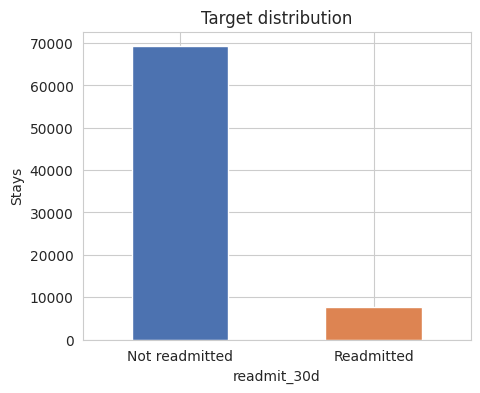

In [6]:
print(train.readmit_30d.value_counts())
print(f"Positive rate: {train.readmit_30d.mean():.3f}")

ax = train.readmit_30d.value_counts().plot.bar(color=['#4C72B0', '#DD8452'], figsize=(5, 4))
ax.set_xticklabels(['Not readmitted', 'Readmitted'], rotation=0)
ax.set_ylabel('Stays')
ax.set_title('Target distribution')
plt.show()

## Missing Values

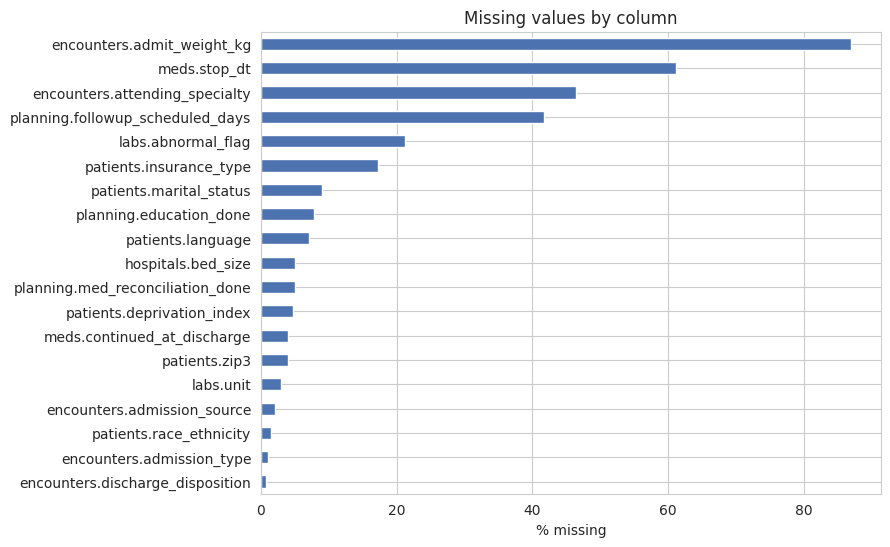

In [7]:
missing = pd.concat([
    encounters.isna().mean().add_prefix('encounters.'),
    patients.isna().mean().add_prefix('patients.'),
    hospitals.isna().mean().add_prefix('hospitals.'),
    planning.isna().mean().add_prefix('planning.'),
    labs.isna().mean().add_prefix('labs.'),
    meds.isna().mean().add_prefix('meds.'),
])
missing = missing[missing > 0].sort_values()

missing.mul(100).plot.barh(figsize=(8, 6), color='#4C72B0')
plt.xlabel('% missing')
plt.title('Missing values by column')
plt.show()

## Data Quality Checks

In [8]:
patients.insurance_type.value_counts(dropna=False)

insurance_type
Medicare      40448
Commercial    30499
NaN           18887
Medicaid       9380
Other          5624
Self-pay       2231
MEDICARE       1214
COMMERCIAL      950
MEDICAID        285
OTHER           193
SELF-PAY         76
Name: count, dtype: int64

In [9]:
patients.race_ethnicity.value_counts(dropna=False)

race_ethnicity
White       62927
Black       19740
Hispanic    14791
Asian        4253
Other        3153
Unknown      2140
NaN          1680
?            1103
Name: count, dtype: int64

In [10]:
print('Birth year = 1900:', (patients.birth_year == 1900).sum())
print('Stays with no discharge planning row:', (~encounters.encounter_id.isin(planning.encounter_id)).sum())

Birth year = 1900: 179
Stays with no discharge planning row: 12235


In [11]:
pd.DataFrame({
    'encounters.admit_dt': encounters.admit_dt.head(3).values,
    'vitals.charttime': vitals.charttime.head(3).values,
    'procedures.proc_dt': procedures.proc_dt.head(3).values,
    'medications.start_dt': meds.start_dt.head(3).values,
})

,encounters.admit_dt,vitals.charttime,procedures.proc_dt,medications.start_dt
0,2019-10-05 17:35:15,03/22/2023 13:58,20-Nov-2021,20211106
1,2021-07-24 22:08:24,03/22/2023 13:58,11-Mar-2020,20190908
2,2019-07-03 06:23:50,03/22/2023 13:58,05-Dec-2021,20201123


In [12]:
diagnoses.icd10_code.sample(12, random_state=SEED).tolist()

['E86.0',
 'I50.32',
 'I2510',
 'E11.10',
 'F32.9',
 'I48.91',
 'E11.65',
 'G47.33',
 'E119',
 'E1165',
 'Z91.19',
 'C801']

In [13]:
labs.groupby(['lab_name', 'unit'], dropna=False).value.median().unstack()

unit,%,10^3/uL,g/L,g/dL,mg/dL,mmol/L,ng/mL,pg/mL,ratio,umol/L,NaN
lab_name,,,,,,,,,,,
Albumin,NaN,NaN,35.0,3.5,NaN,NaN,NaN,NaN,NaN,NaN,3.900
Bnp,NaN,NaN,NaN,NaN,NaN,NaN,NaN,687.0,NaN,NaN,648.000
Bun,NaN,NaN,NaN,NaN,21.00,NaN,NaN,NaN,NaN,NaN,21.000
Creatinine,NaN,NaN,NaN,NaN,1.18,NaN,NaN,NaN,NaN,105.0,1.360
Glucose,NaN,NaN,NaN,NaN,137.00,7.6,NaN,NaN,NaN,NaN,129.000
Hba1C,7.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.500
Hemoglobin,NaN,NaN,121.0,12.1,NaN,NaN,NaN,NaN,NaN,NaN,13.300
Inr,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.15,NaN,1.150
Lactate,NaN,NaN,NaN,NaN,NaN,2.4,NaN,NaN,NaN,NaN,2.300


In [14]:
vitals.groupby('vital_type').value.describe()

,count,mean,std,min,25%,50%,75%,max
vital_type,,,,,,,,
DBP,377723.0,79.175195,11.753826,28.0,71.0,79.0,87.0,130.0
HR,377607.0,80.181586,13.787702,29.0,71.0,80.0,89.0,300.0
RR,377833.0,18.017759,2.808955,7.0,16.0,18.0,20.0,32.0
SBP,377926.0,128.805330,16.739113,57.0,118.0,129.0,140.0,210.0
SPO2,378181.0,95.744099,2.953330,0.0,94.0,96.0,97.0,100.0
TEMP,378097.0,47.722074,23.429920,35.2,36.7,37.0,37.4,101.1


## Data Cleaning

In [15]:
patients['insurance_type'] = patients.insurance_type.str.upper()
patients['race_ethnicity'] = patients.race_ethnicity.replace({'?': 'Unknown'})
patients.loc[patients.birth_year <= 1900, 'birth_year'] = np.nan

encounters['admit_dt'] = pd.to_datetime(encounters.admit_dt)
encounters['discharge_dt'] = pd.to_datetime(encounters.discharge_dt)

planning['home_health_referral'] = (planning.home_health_referral == 'Y').astype(int)
planning['education_done'] = planning.education_done.map({'Yes': 1, 'No': 0})

## Feature Construction

In [16]:
df = (encounters
      .merge(patients, on='patient_id', how='left')
      .merge(hospitals, on='hospital_id', how='left')
      .merge(planning, on='encounter_id', how='left'))

df['age'] = df.admit_dt.dt.year - df.birth_year
df['los_days'] = (df.discharge_dt - df.admit_dt).dt.total_seconds() / 86400

counts = {
    'n_diagnoses': diagnoses.groupby('encounter_id').size(),
    'n_procedures': procedures.groupby('encounter_id').size(),
    'n_labs': labs.groupby('encounter_id').size(),
    'n_labs_abnormal': labs[labs.abnormal_flag.isin(['H', 'L'])].groupby('encounter_id').size(),
    'n_vitals': vitals.groupby('encounter_id').size(),
    'n_medications': meds.groupby('encounter_id').size(),
    'n_meds_at_discharge': meds[meds.continued_at_discharge == 1].groupby('encounter_id').size(),
    'n_unit_transfers': transfers.groupby('encounter_id').size(),
    'n_icu_stays': transfers[transfers.unit == 'ICU'].groupby('encounter_id').size(),
}
for name, s in counts.items():
    df[name] = df.encounter_id.map(s).fillna(0)

prior_counts = pd.crosstab(prior.patient_id, prior.visit_type).add_prefix('prior_')
df = df.merge(prior_counts, left_on='patient_id', right_index=True, how='left')
df[prior_counts.columns] = df[prior_counts.columns].fillna(0)

df.shape

(109787, 42)

In [17]:
num_cols = ['age', 'los_days', 'deprivation_index', 'bed_size', 'teaching_flag',
            'n_diagnoses', 'n_procedures', 'n_labs', 'n_labs_abnormal', 'n_vitals',
            'n_medications', 'n_meds_at_discharge', 'n_unit_transfers', 'n_icu_stays',
            'prior_ED', 'prior_IP', 'prior_OP',
            'followup_scheduled_days', 'home_health_referral', 'med_reconciliation_done', 'education_done']
cat_cols = ['hospital_id', 'admission_type', 'admission_source', 'service_line', 'discharge_disposition',
            'attending_specialty', 'sex', 'race_ethnicity', 'language', 'marital_status',
            'insurance_type', 'urban_rural', 'ownership']

X = train[['encounter_id']].merge(df, on='encounter_id', how='left')
y = train.readmit_30d
X_test = test[['encounter_id']].merge(df, on='encounter_id', how='left')

print(X.shape, X_test.shape, len(num_cols) + len(cat_cols), 'features')

(76975, 42) (32812, 42) 34 features


## Exploratory Data Analysis

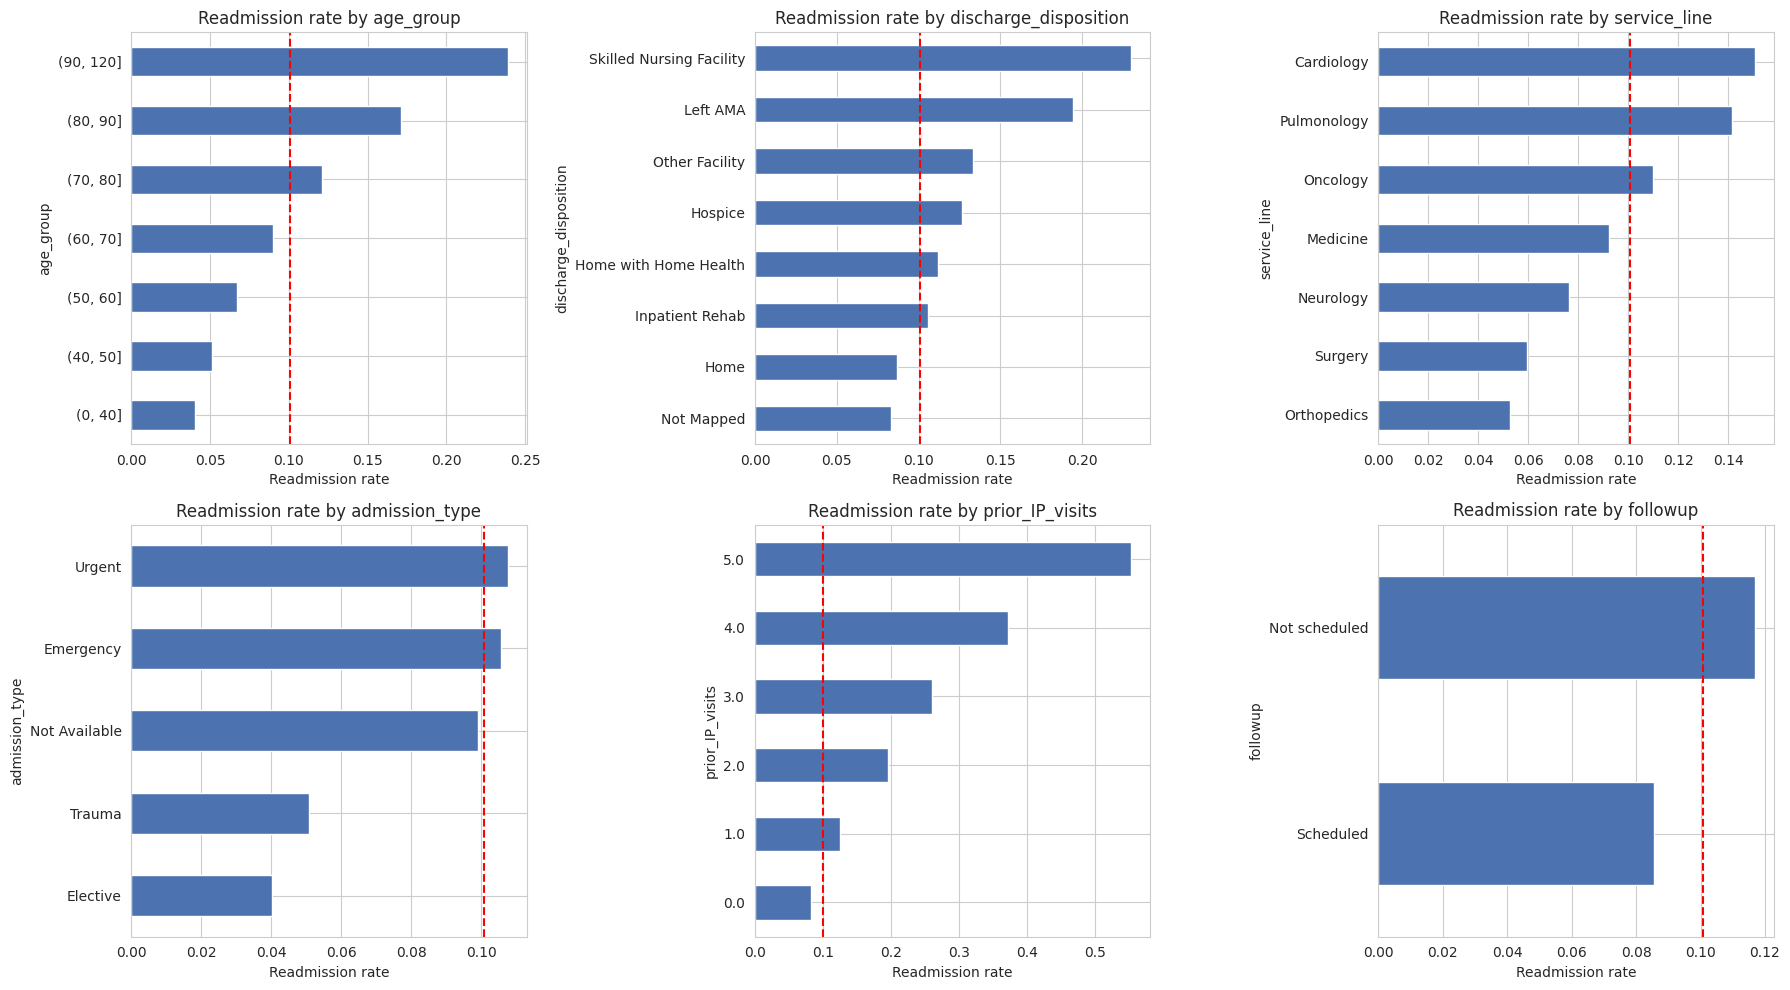

In [18]:
eda = X.assign(readmit=y.values)
eda['age_group'] = pd.cut(eda.age, [0, 40, 50, 60, 70, 80, 90, 120])
eda['followup'] = np.where(eda.followup_scheduled_days.isna(), 'Not scheduled', 'Scheduled')
eda['prior_IP_visits'] = eda.prior_IP.clip(upper=5)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flat, ['age_group', 'discharge_disposition', 'service_line',
                                'admission_type', 'prior_IP_visits', 'followup']):
    eda.groupby(col, observed=True).readmit.mean().sort_values().plot.barh(ax=ax, color='#4C72B0')
    ax.axvline(y.mean(), color='red', linestyle='--')
    ax.set_title(f'Readmission rate by {col}')
    ax.set_xlabel('Readmission rate')
plt.tight_layout()
plt.show()

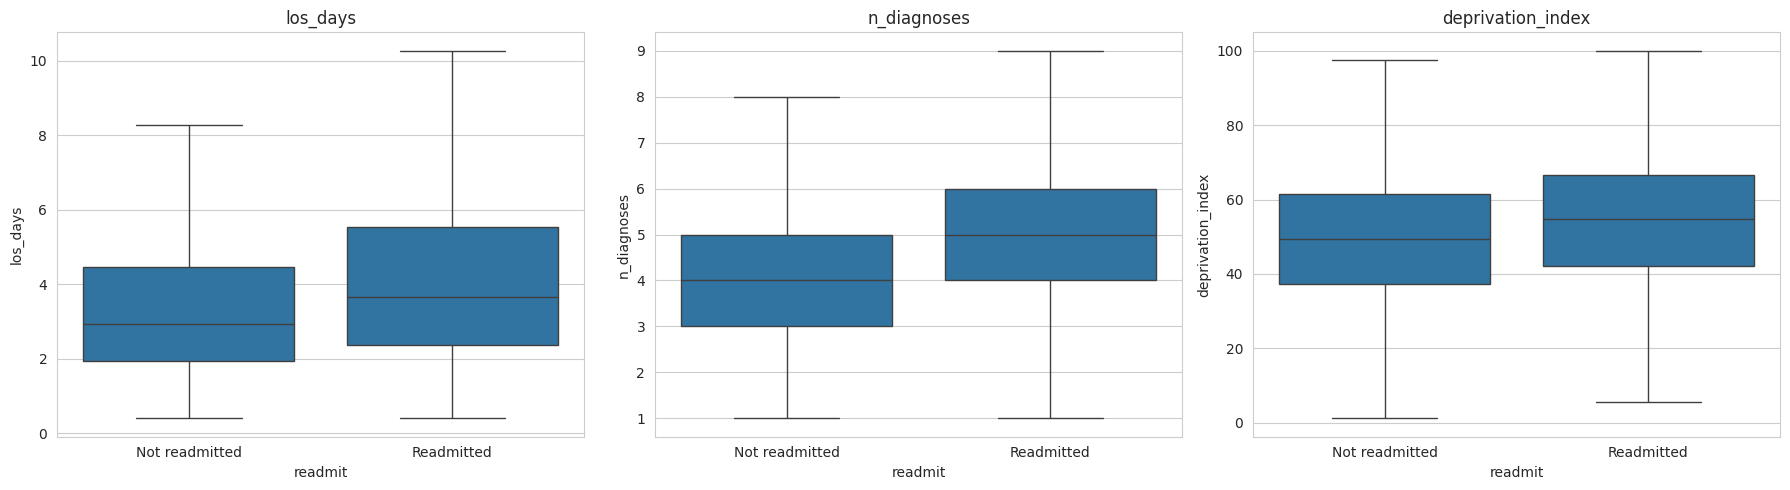

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ['los_days', 'n_diagnoses', 'deprivation_index']):
    sns.boxplot(data=eda, x='readmit', y=col, ax=ax, showfliers=False)
    ax.set_xticklabels(['Not readmitted', 'Readmitted'])
    ax.set_title(col)
plt.tight_layout()
plt.show()

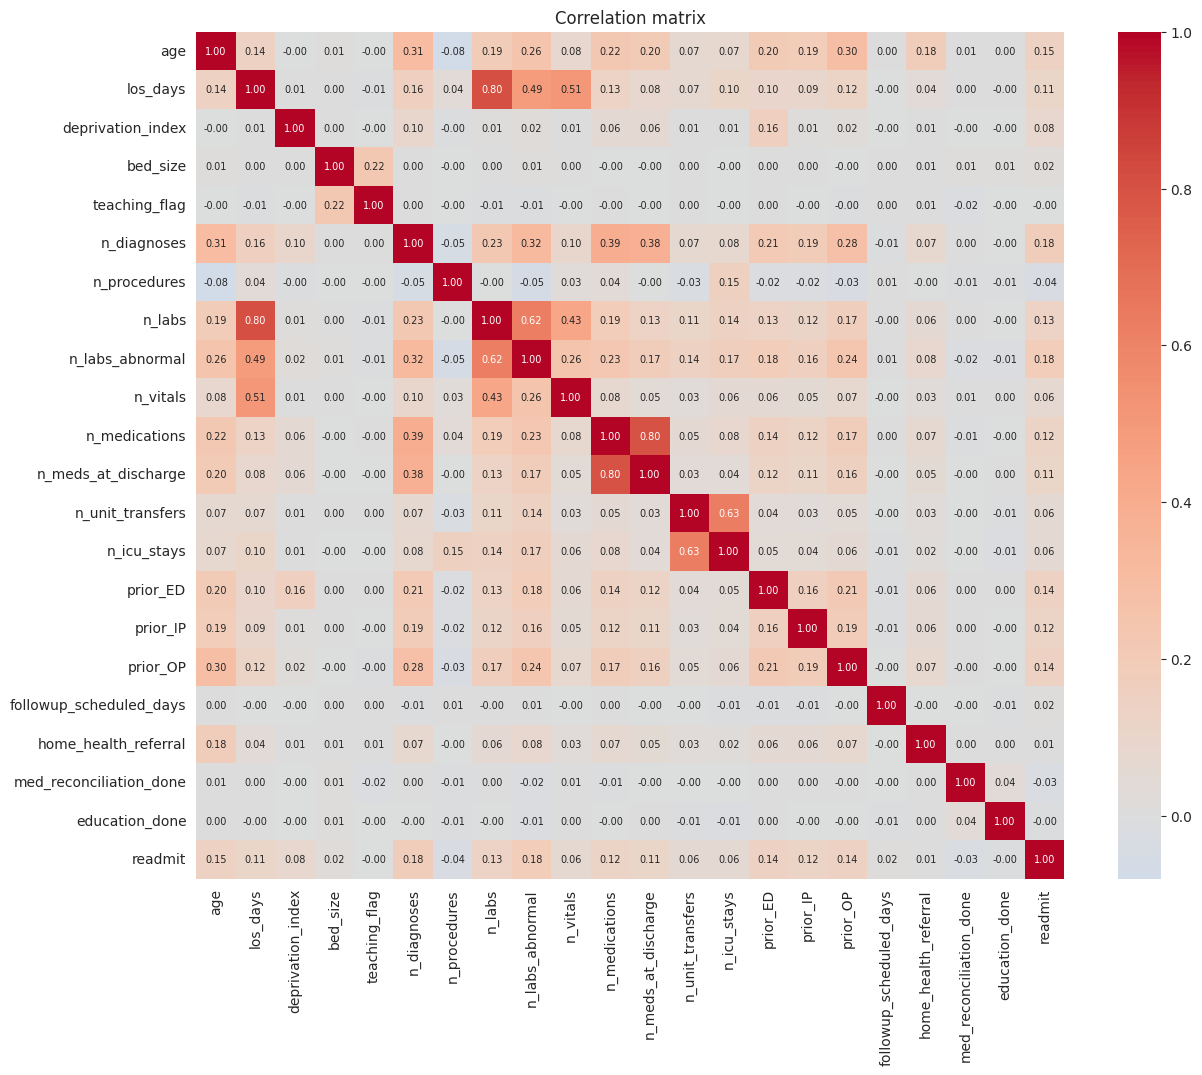

In [20]:
corr = eda[num_cols + ['readmit']].corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Correlation matrix')
plt.show()

In [21]:
corr.readmit.drop('readmit').sort_values(key=abs, ascending=False).round(3)

n_labs_abnormal            0.183
n_diagnoses                0.181
age                        0.146
prior_ED                   0.142
prior_OP                   0.140
n_labs                     0.130
n_medications              0.122
prior_IP                   0.120
los_days                   0.106
n_meds_at_discharge        0.106
deprivation_index          0.085
n_vitals                   0.064
n_unit_transfers           0.062
n_icu_stays                0.060
n_procedures              -0.038
med_reconciliation_done   -0.027
bed_size                   0.024
followup_scheduled_days    0.016
home_health_referral       0.008
education_done            -0.005
teaching_flag             -0.002
Name: readmit, dtype: float64

## Preprocessing

In [22]:
numeric = Pipeline([('impute', SimpleImputer(strategy='median')),
                    ('scale', StandardScaler())])
categorical = Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='Missing')),
                        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
preprocess = ColumnTransformer([('num', numeric, num_cols),
                                ('cat', categorical, cat_cols)])

## Baseline Models

In [23]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=SEED),
    'Naive Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier(n_jobs=-1, random_state=SEED),
}

## Cross-Validation

In [24]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

results, oof = [], {}
for name, model in models.items():
    pipe = Pipeline([('prep', preprocess), ('model', clone(model))])
    pred = np.zeros(len(X))
    aucs, accs = [], []
    for tr_idx, va_idx in cv.split(X, y):
        pipe.fit(X.iloc[tr_idx], y.iloc[tr_idx])
        p = pipe.predict_proba(X.iloc[va_idx])[:, 1]
        pred[va_idx] = p
        aucs.append(roc_auc_score(y.iloc[va_idx], p))
        accs.append(accuracy_score(y.iloc[va_idx], p >= 0.5))
    oof[name] = pred
    results.append({'Model': name, 'CV ROC-AUC': np.mean(aucs), 'Std': np.std(aucs), 'Accuracy': np.mean(accs)})
    print(f'{name:20s} ROC-AUC {np.mean(aucs):.4f} ± {np.std(aucs):.4f}')

results = pd.DataFrame(results).sort_values('CV ROC-AUC', ascending=False).reset_index(drop=True)
print(f"\nMajority-class accuracy: {1 - y.mean():.4f}")
results

Logistic Regression  ROC-AUC 0.7363 ± 0.0080
KNN                  ROC-AUC 0.5980 ± 0.0041
Decision Tree        ROC-AUC 0.5465 ± 0.0053
Naive Bayes          ROC-AUC 0.6798 ± 0.0056
Random Forest        ROC-AUC 0.7037 ± 0.0052

Majority-class accuracy: 0.8993


,Model,CV ROC-AUC,Std,Accuracy
0,Logistic Regression,0.736264,0.008042,0.901552
1,Random Forest,0.703721,0.005234,0.900591
2,Naive Bayes,0.679809,0.005633,0.649704
3,KNN,0.598038,0.004051,0.894394
4,Decision Tree,0.546499,0.005339,0.825034


## Model Comparison

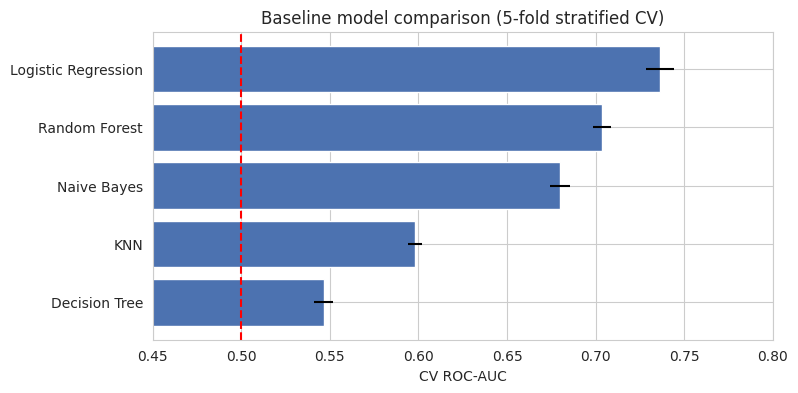

In [25]:
plt.figure(figsize=(8, 4))
plt.barh(results.Model, results['CV ROC-AUC'], xerr=results.Std, color='#4C72B0')
plt.axvline(0.5, color='red', linestyle='--')
plt.xlim(0.45, 0.8)
plt.xlabel('CV ROC-AUC')
plt.title('Baseline model comparison (5-fold stratified CV)')
plt.gca().invert_yaxis()
plt.show()

## ROC Curves

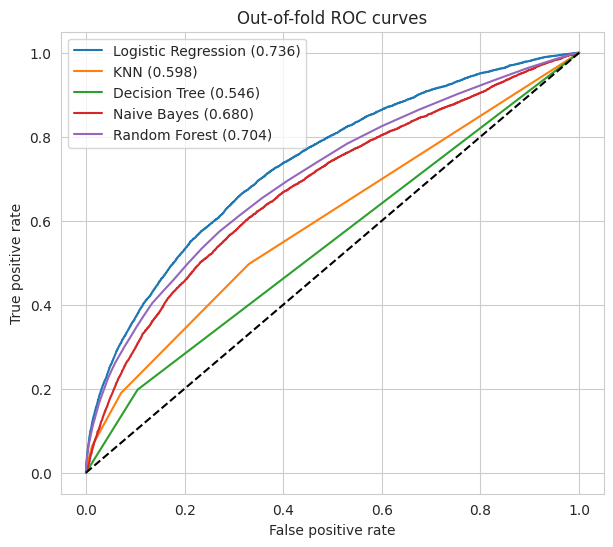

In [26]:
plt.figure(figsize=(7, 6))
for name, p in oof.items():
    fpr, tpr, _ = roc_curve(y, p)
    plt.plot(fpr, tpr, label=f'{name} ({roc_auc_score(y, p):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('Out-of-fold ROC curves')
plt.legend()
plt.show()

## Random Forest Feature Importance

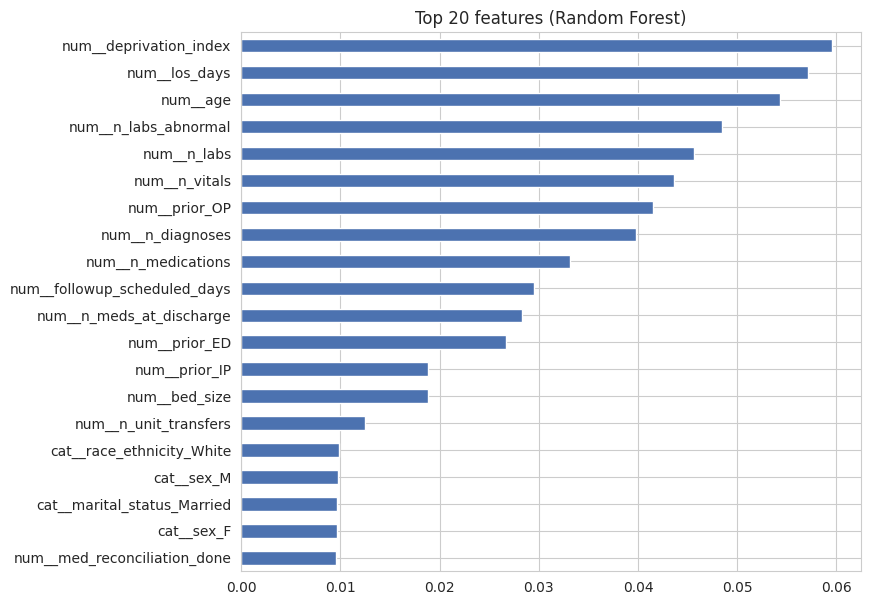

In [27]:
rf = Pipeline([('prep', preprocess), ('model', clone(models['Random Forest']))]).fit(X, y)
names = rf.named_steps['prep'].get_feature_names_out()
importance = pd.Series(rf.named_steps['model'].feature_importances_, index=names).sort_values()

importance.tail(20).plot.barh(figsize=(8, 7), color='#4C72B0')
plt.title('Top 20 features (Random Forest)')
plt.show()

## Final Model

In [28]:
best_name = results.loc[0, 'Model']
final = Pipeline([('prep', preprocess), ('model', clone(models[best_name]))])
final.fit(X, y)
print('Selected model:', best_name)

Selected model: Logistic Regression


## Submission File

In [29]:
submission = pd.DataFrame({'encounter_id': X_test.encounter_id,
                           'readmit_30d': final.predict_proba(X_test)[:, 1]})
submission.to_csv('/kaggle/working/submission.csv', index=False)
print(submission.shape)
submission.head()

(32812, 2)


,encounter_id,readmit_30d
0,E14322700,0.088853
1,E10891017,0.067709
2,E15846764,0.116318
3,E35399048,0.145993
4,E18403456,0.035309
